# Blast vs ARFCAMB: single Gaussian bin

Validation of Blast's angular redshift fluctuations (ARF) against [ARFCAMB](https://github.com/chmATiac/ARFCAMB) (branch `version_March11th_2025`), for one Gaussian bin with $z_0 = 1$, $\sigma = 0.2$. It uses the same pieces as `NewBlastTheory/blARF_cls.ipynb`.

* **Reference build:** ARFCAMB with `patches/arfcamb_no_gauge_term.patch` applied. The patch drops the Newtonian-gauge correction $(\dots - 3\mathcal H)\sigma/k$ from the counts density source, leaving $b\,\delta_c^{\rm sync}$, which is what Blast's `NumberCounts` models.
* The CAMB side, including the **linear** $P(k,z)$ that Blast consumes here, comes from `generate_camb_reference.py`. So this compares kernels and projections only, not the power spectrum.
* The Blast side is `blast_pieces.jl`, the same code the test `test/test_arfcamb_validation.jl` runs.
* Differences are shown as $(C^{\rm Blast}_\ell - C^{\rm CAMB}_\ell)/\sqrt{C^{aa}_\ell C^{bb}_\ell}$, which is well defined for crosses that pass through zero.

Blast's ARF kernel is density-only, $(z-\bar z)\,K^\delta$. The strict ARF pieces (`zz`, `dz`, `kz`) are therefore CAMB runs with `counts_density` only.

In [1]:
using Pkg
Pkg.activate(@__DIR__)
using Blast, NPZ, TOML, Plots, LaTeXStrings, Printf
include("blast_pieces.jl")

  Activating project at `~/Desktop/Blast.jl/validation/arfcamb`


Dict{String, Tuple{String, String}} with 11 entries:
  "dz"     => ("dd", "zz")
  "kd_mu"  => ("kk", "dd_mu")
  "kd_rsd" => ("kk", "dd_rsd")
  "zz"     => ("zz", "zz")
  "dd"     => ("dd", "dd")
  "dd_mu"  => ("dd_mu", "dd_mu")
  "kd"     => ("kk", "dd")
  "kz"     => ("kk", "zz")
  "dd_rsd" => ("dd_rsd", "dd_rsd")
  "gg"     => ("gg", "gg")
  "kg"     => ("kk", "gg")

In [2]:
cfg = TOML.parsefile("config.toml")
fx = npzread(joinpath("..", "..", "test", "reference_fixtures", "arfcamb", "gaussian_z1.npz"))
ℓ = fx["ell"]
@printf("zbar (ARFCAMB's Σ zW / Σ W) = %.8f\n", fx["zbar"][1])

zbar (ARFCAMB's Σ zW / Σ W) = 1.00000029


## Blast $C_\ell$ (P(k) of CDM+baryons, the default; total matter for comparison)

In [3]:
blast = blast_arf_pieces(cfg, fx)                  # matter = :cb
blast_tot = blast_arf_pieces(cfg, fx; matter=:tot)

Dict{String, Vector{Float64}} with 11 entries:
  "zz"     => [3.40289e-8, 3.64317e-8, 3.87893e-8, 4.12906e-8, 4.3932e-8, 4.654…
  "dd"     => [1.01822e-6, 1.16092e-6, 1.30535e-6, 1.45071e-6, 1.59505e-6, 1.73…
  "dd_mu"  => [1.00089e-6, 1.14197e-6, 1.28294e-6, 1.42393e-6, 1.5635e-6, 1.698…
  "kz"     => [-8.74957e-9, -1.15711e-8, -1.4153e-8, -1.64793e-8, -1.85601e-8, …
  "dd_rsd" => [1.8846e-6, 1.93298e-6, 1.99555e-6, 2.06774e-6, 2.14595e-6, 2.228…
  "gg"     => [1.87789e-6, 1.92343e-6, 1.98139e-6, 2.0482e-6, 2.12077e-6, 2.197…
  "dz"     => [-3.73787e-8, -4.6408e-8, -5.53951e-8, -6.39684e-8, -7.19819e-8, …
  "kd_mu"  => [4.66998e-8, 7.31111e-8, 9.91827e-8, 1.2455e-7, 1.48998e-7, 1.723…
  "kd_rsd" => [9.47254e-8, 1.27129e-7, 1.56993e-7, 1.84855e-7, 2.10961e-7, 2.35…
  "kd"     => [9.24839e-8, 1.24307e-7, 1.54304e-7, 1.82477e-7, 2.08877e-7, 2.33…
  "kg"     => [4.89412e-8, 7.59328e-8, 1.01872e-7, 1.26929e-7, 1.51083e-7, 1.74…

In [4]:
default(lw=2, framestyle=:box, grid=false, legendfontsize=9, guidefontsize=11, tickfontsize=9)

const LABELS = Dict(
    "dd" => L"\delta\delta", "dd_rsd" => L"(\delta{+}\mathrm{RSD})^2", "dd_mu" => L"(\delta{+}\mu)^2",
    "gg" => L"gg\ (\delta{+}\mathrm{RSD}{+}\mu)", "kd" => L"\kappa\delta", "kd_rsd" => L"\kappa(\delta{+}\mathrm{RSD})",
    "kd_mu" => L"\kappa(\delta{+}\mu)", "kg" => L"\kappa g", "zz" => L"zz\ (\mathrm{ARF})", "dz" => L"\delta z",
    "kz" => L"\kappa z",
)

function compare_panel(key; camb_key=key, extra=nothing)
    a, b = ARFCAMB_NORMS[key]
    top = plot(ℓ, abs.(fx[camb_key]), xscale=:log10, yscale=:log10, color=:black, label="ARFCAMB",
        ylabel=L"|C_\ell|", title=LABELS[key], xformatter=_->"")
    plot!(top, ℓ, abs.(blast[key]), color=:crimson, ls=:dash, label="Blast")
    Δ = normalized_difference(blast[key], fx[camb_key], fx[a], fx[b])
    bot = plot(ℓ, 100 .* Δ, xscale=:log10, color=:crimson, label="", ylims=(-3, 3),
        xlabel=L"\ell", ylabel=L"\Delta\ [\%]")
    hspan!(bot, [-0.5, 0.5], color=:gray, alpha=0.2, label="")
    hline!(bot, [0], color=:black, lw=1, label="")
    if extra !== nothing
        plot!(bot, ℓ, 100 .* normalized_difference(extra[key], fx[camb_key], fx[a], fx[b]),
            color=:royalblue, lw=1.5, label="Blast, P_tot")
    end
    plot(top, bot, layout=grid(2, 1, heights=[0.65, 0.35]), link=:x)
end;

## Galaxy clustering autos (baseline)
Gray band: ±0.5%. Blue: Blast with total-matter P(k), which comes out ~1% low, as expected with mν = 0.06 eV.

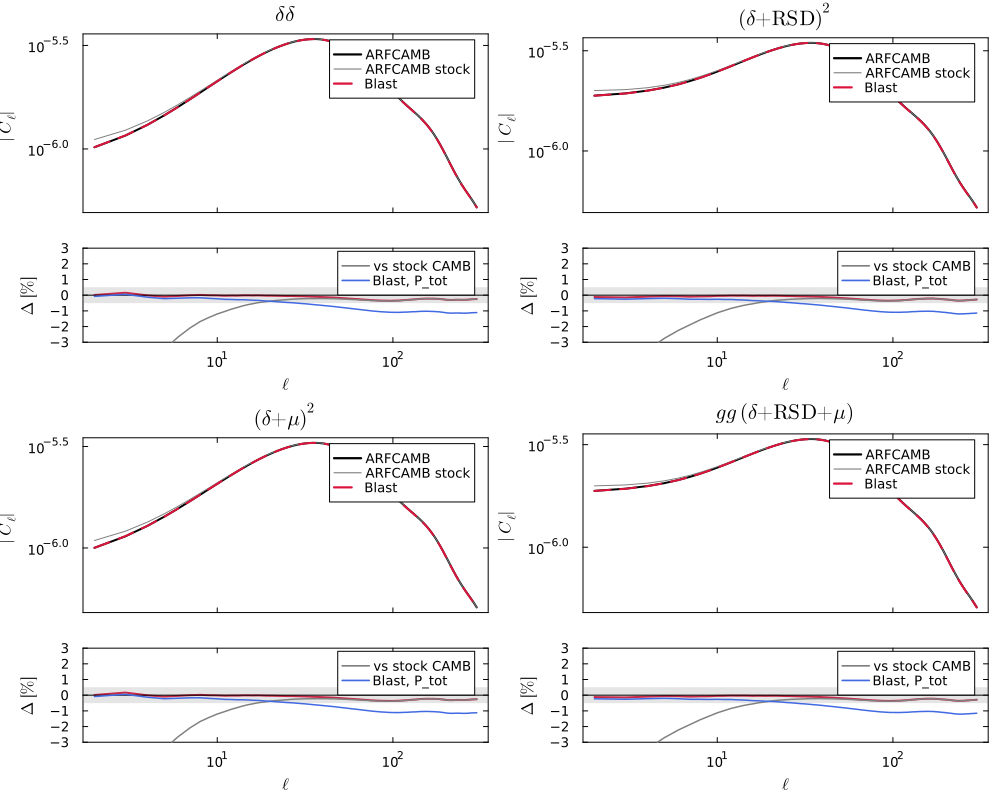

In [5]:
plot([compare_panel(k; extra=blast_tot) for k in ("dd", "dd_rsd", "dd_mu", "gg")]..., layout=(2, 2), size=(1000, 800))

## CMB lensing × galaxy clustering

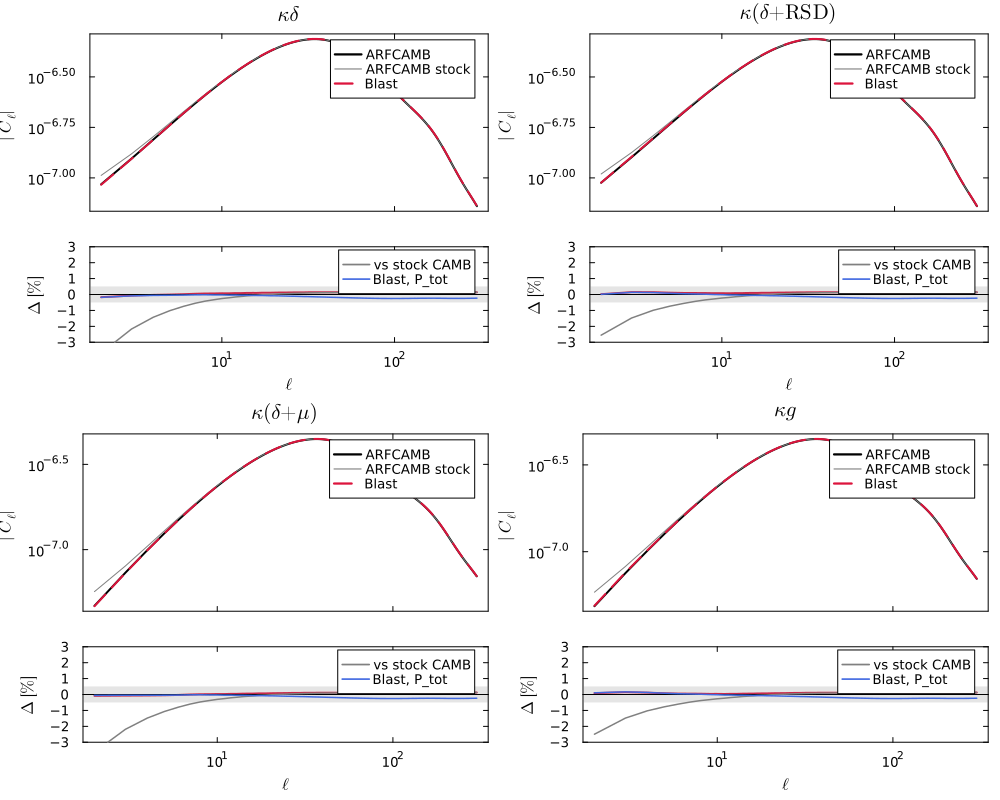

In [6]:
plot([compare_panel(k; extra=blast_tot) for k in ("kd", "kd_rsd", "kd_mu", "kg")]..., layout=(2, 2), size=(1000, 800))

## ARF (density-only)

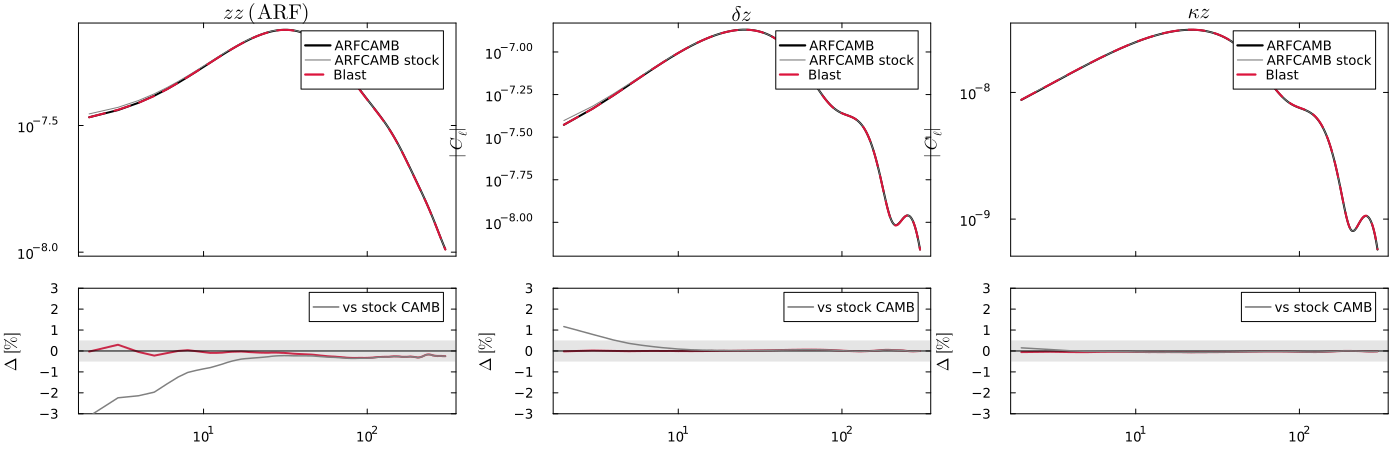

In [7]:
plot([compare_panel(k) for k in ("zz", "dz", "kz")]..., layout=(1, 3), size=(1400, 450))

## For information: Blast's density-only ARF vs ARFCAMB's full ARF

With `counts_redshift` and `counts_lensing` on, ARFCAMB also includes ARF-weighted RSD (the line-of-sight velocity term) and magnification. Blast's ARF kernel does not model these. The gap below measures how large those terms are. It is not a validation failure.

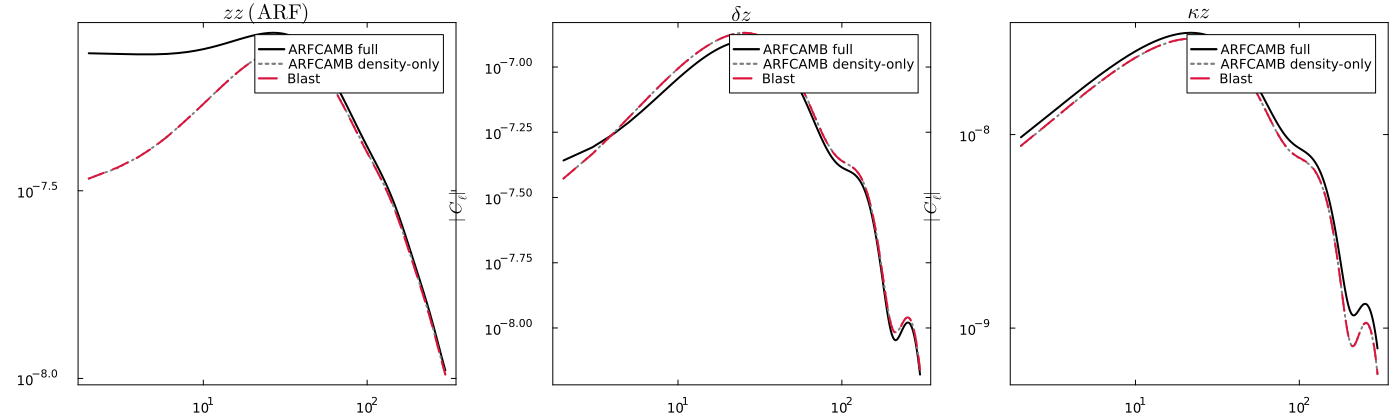

In [8]:
p = plot(layout=(1, 3), size=(1400, 420))
for (i, (key, full)) in enumerate((("zz", "zz_full"), ("dz", "dz_full"), ("kz", "kz_full")))
    plot!(p[i], ℓ, abs.(fx[full]), xscale=:log10, yscale=:log10, color=:black, label="ARFCAMB full",
        title=LABELS[key], xlabel=L"\ell", ylabel=L"|C_\ell|")
    plot!(p[i], ℓ, abs.(fx[key]), color=:gray, ls=:dot, label="ARFCAMB density-only")
    plot!(p[i], ℓ, abs.(blast[key]), color=:crimson, ls=:dash, label="Blast")
end
p

## Summary table: max |Δ| per ℓ range

In [9]:
@printf("%-7s %12s %12s\n", "piece", "ℓ∈[2,10)", "ℓ∈[10,300]")
for key in ("dd", "dd_rsd", "dd_mu", "gg", "kd", "kd_rsd", "kd_mu", "kg", "zz", "dz", "kz")
    a, b = ARFCAMB_NORMS[key]
    Δ = abs.(normalized_difference(blast[key], fx[key], fx[a], fx[b]))
    @printf("%-7s %11.2f%% %11.2f%%\n", key, 100maximum(Δ[ℓ .< 10]), 100maximum(Δ[ℓ .>= 10]))
end

piece       ℓ∈[2,10)   ℓ∈[10,300]  stock CAMB, ℓ=2
dd             0.16%        0.35%           -8.97%
dd_rsd         0.14%        0.35%           -6.13%
dd_mu          0.17%        0.37%           -8.62%
gg             0.14%        0.37%           -5.89%
kd             0.17%        0.16%           -3.67%
kd_rsd         0.15%        0.16%           -2.55%
kd_mu          0.08%        0.14%           -3.62%
kg             0.15%        0.14%           -2.49%
zz             0.30%        0.33%           -3.12%
dz             0.02%        0.06%            1.17%
kz             0.06%        0.06%            0.15%
